# SDF Frontier & Three Inventions

**Workstream:** research and invention notebook for the Marble Madness SDF remake.
**Engine contract:** one analytical field $\mathcal{W}(\mathbf{p}, t)$ evaluated in lockstep by the WebGPU raymarcher and the 120 Hz CPU physics kernel (`src/sdf/eval-cpu.ts`, `src/sdf/jet-sdf.ts`).

This notebook does two things:

1. Place the shipped games and papers that actually use signed distance fields on one plot, against the architectural limit of each system.
2. Derive, implement, and measure three constructions that those systems do not ship: a **symplectic jet** through smooth CSG, a **Lipschitz portal field**, and a **curvature-bounded march** with an $O(1)$ brick residual.

Scores on the frontier plot are a rubric, not a lab instrument. Every timing, normal error, Lipschitz ratio, and step count below is computed in this notebook.

## Where the field actually is

| System | What the SDF is | Hard limit |
| :--- | :--- | :--- |
| **Claybook** (Second Order, Sebastian Aaltonen, GDC 2018) | World volume $1024\times1024\times512$, 8-bit, five mip levels, 586 MB. Range $[-4,+4]$ voxels, so 256 codes across 8 voxels: about $1/32$ voxel. Brushes $32^3$–$128^3$ combined with exponential smooth min/max. Sparse $8^3$ tiles; mips re-expanded with the eikonal equation. | The field is a quantized grid. Clay and fluid are GPU particles (up to 16k per shape, 64k SPH), not a closed-form $C^\infty$ primitive with an exact normal. No non-Euclidean portal metric. |
| **Dreams** (Media Molecule, Alex Evans, SIGGRAPH 2015, *Learning from Failure*) | User edits are CSG trees (add, subtract, soft-add) evaluated to SDFs, then splatted to multi-resolution point clouds. Flecks sit on a brick hull. The PS4 renderer is compute, not triangles. | The picture is a fleck cloud. Physics does not roll on the live analytical field, and the representation is Euclidean. |
| **Teardown** (Dennis Gustafsson, Voxagon) | Dense voxel volumes at about 10 cm, one material byte per voxel, ray-marched on a 1-bit occupancy bitmap. AO, soft shadows, specular occlusion. Destruction is integer and well-behaved. The 2024 engine moves to sparse $8^3$ chunks and hardware ray tracing, still on voxels. | Normals are discrete cell faces. A marble cannot ride a $C^\infty$ fillet; there is no analytical surface velocity. |
| **UE5 Lumen / Mesh Distance Fields** (Wright et al., SIGGRAPH 2022) | Per-mesh narrow-band SDFs, $[-4,+4]$ in one byte, sparse $8^3$ bricks. Global SDF is four camera clipmaps of $256^3$. Software rays use the mesh SDF up close and the global field after that. | Primary visibility is Nanite / raster triangles. Gameplay collision is Chaos (or a mesh collider), not the distance field. The SDF is a lighting proxy. |
| **Shadertoy analytical SDFs** (Inigo Quilez) | Exact primitives, polynomial smooth-minimum (quadratic published 2013; the cubic and circular kernels later), and analytic $\nabla \mathrm{smin}$ so a shader can light without a 4-tap stencil. Enhanced sphere tracing (Keinert, Schäfer, Korndörfer, Ganse, Stamminger, 2014) over-relaxes the march. | The CPU gameplay loop never sees the field. There is no 120 Hz contact solver, no kinematic surface velocity, and no live level mutation. |
| **Neural implicit SDFs** | Instant-NGP (Müller, Evans, Schied, Keller, SIGGRAPH 2022) hash grids; SIREN sine MLPs; Neuralangelo (Li et al., CVPR 2023) hash grids plus numerical gradients; NeuS2 for faster training. BakedSDF (Yariv et al., 2023) then **meshes** the field so a rasterizer and a physics engine can run. | A network or a bake. Inference is the wrong cost model for a 120 Hz marble, and a bake throws away live CSG. Lipschitz-1 is not guaranteed. |

**The empty corner** is a field that is simultaneously (1) an exact analytical jet a CPU physics step can trust and (2) mutable in topology and in the metric of space, including portals and a 1M-token course synthesizer. That corner is what the three inventions below are for.


In [1]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LightSource, LinearSegmentedColormap
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401  (registers 3d projection)

cwd = Path.cwd()
FIG = (cwd / "figures") if cwd.name == "notebooks" else (cwd / "notebooks" / "figures")
FIG.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.facecolor": "#f6f1e7",
    "axes.facecolor": "#fffdf8",
    "axes.edgecolor": "#2a2622",
    "axes.labelcolor": "#1f1b16",
    "text.color": "#1f1b16",
    "xtick.color": "#2a2622",
    "ytick.color": "#2a2622",
    "axes.titleweight": "medium",
    "axes.titlesize": 13,
    "font.size": 11,
    "font.family": "DejaVu Sans",
    "axes.grid": False,
    "savefig.dpi": 160,
    "savefig.bbox": "tight",
    "savefig.facecolor": "#f6f1e7",
})

INK = "#1f1b16"
AMBER = "#c46b1a"
TEAL = "#0f6e6e"
CRIMSON = "#9c2f2f"
NAVY = "#243e73"
FIELD_CMAP = LinearSegmentedColormap.from_list(
    "sdf", ["#9c2f2f", "#f3d2b0", "#fffdf8", "#b7d4d2", "#0f6e6e"]
)

SUMMARY = {}
print("notebook ready", FIG.resolve())


notebook ready /workspace/notebooks/figures


## Invention 1 — Symplectic Jet-SDF (`jSDF`)

Quilez already differentiates the **spatial** smooth-minimum: if $f=\mathrm{smin}(a,b)$ then $\nabla f = w_A \nabla a + w_B \nabla b$ with $w_A+w_B=1$ and $0\le w\le 1$. That kills the 4-tap normal inside a shader. It does not answer the question a 120 Hz marble asks when a rising bridge fillet melts into a moving Steelie:

$$
\nabla d \cdot \mathbf{v}_{\text{surf}} + \partial_t d = 0.
$$

The launch direction is the velocity of the **zero level set**, not a lerp of the two rigid velocities. Inside the meniscus $\|\nabla d\|<1$, so the normal speed is amplified by $1/\|\nabla d\|$.

### Quadratic kernel used by this engine

`eval-cpu.ts` and `jet-sdf.ts` use the band form (Quilez's quadratic with the factor of 4 absorbed into $k$):

$$
h=\frac{\max(k-|a-b|,0)}{k},\qquad
f=\min(a,b)-\frac{k}{4}h^{2}.
$$

Inside the band, with $a\le b$ so $|a-b|=b-a$ and $\partial h/\partial a=1/k$, $\partial h/\partial b=-1/k$:

$$
\frac{\partial f}{\partial a}=1-\frac{h}{2},\qquad \frac{\partial f}{\partial b}=\frac{h}{2}.
$$

The cubic kernel $f=\min(a,b)-(k/6)h^{3}$ gives weights $1-h^{2}/2$ and $h^{2}/2$. Outside the band the operator is exactly $\min$, so the field is rigid (CD family): shapes are not distorted until they are within $k$.

### The jet we add

Children carry $(d, \nabla d, \partial_t d)$. The chain rule has no extra term when $k$ is constant:

$$
\partial_t f = w_A\,\partial_t a + w_B\,\partial_t b,\qquad
\nabla f = w_A\nabla a + w_B\nabla b.
$$

A rigid child with center velocity $\mathbf{v}_{c}$ has $\partial_t d = -\nabla d\cdot\mathbf{v}_{c}$ plus any explicit deformation (the wave floor). The zero-level velocity is then

$$
\mathbf{v}_{\text{surf}} = v_n\,\mathbf{n}+\mathbf{v}_{\parallel},\qquad
v_n = -\frac{\partial_t f}{\|\nabla f\|},\qquad
\mathbf{n}=\frac{\nabla f}{\|\nabla f\|},
$$

with $\mathbf{v}_{\parallel}$ the tangential part of the blended rigid motion. The identity $\nabla f\cdot\mathbf{v}_{\text{surf}}+\partial_t f=0$ holds by construction. Inside the fillet $\|\nabla f\|<1$, so the normal speed is $v_n=-\partial_t f/\|\nabla f\|$: the same time derivative, stretched by $1/\|\nabla f\|$. A lerp of the two rigid velocities does not satisfy the identity.

The same weights give a curvature proxy for Invention 3 at no extra cost: fillet activation $4 w_A w_B = h(1-h)$ for the quadratic kernel, since $w_A w_B=(h/2)(1-h/2)$ is not quite $h(1-h)/4$ — we store $4 w_A w_B$, which peaks at 1 when $w_A=w_B=1/2$ (the mid-fillet, $h=1$).


In [2]:
def _as3(p):
    return np.asarray(p, dtype=np.float64)


def jet_sphere(p, radius):
    p = _as3(p)
    length = np.linalg.norm(p)
    if length < 1e-12:
        return -radius, np.array([0.0, 1.0, 0.0])
    g = p / length
    return float(length - radius), g


def jet_box(p, half):
    p = _as3(p)
    half = _as3(half)
    sign = np.where(p < 0.0, -1.0, 1.0)
    q = np.abs(p) - half
    outer = np.maximum(q, 0.0)
    out_len = np.linalg.norm(outer)
    if out_len > 1e-12:
        return float(out_len), sign * outer / out_len
    axis = int(np.argmax(q))
    g = np.zeros(3)
    g[axis] = sign[axis]
    return float(q[axis]), g


def jet_cylinder(p, radius, half_height):
    p = _as3(p)
    rxz = float(np.hypot(p[0], p[2]))
    rx = p[0] / rxz if rxz > 1e-12 else 1.0
    rz = p[2] / rxz if rxz > 1e-12 else 0.0
    sy = -1.0 if p[1] < 0.0 else 1.0
    dx = rxz - radius
    dy = abs(p[1]) - half_height
    mx, my = max(dx, 0.0), max(dy, 0.0)
    out_len = float(np.hypot(mx, my))
    if out_len > 1e-12:
        gr = mx / out_len
        return out_len, np.array([rx * gr, sy * my / out_len, rz * gr])
    if dx > dy:
        return float(dx), np.array([rx, 0.0, rz])
    return float(dy), np.array([0.0, sy, 0.0])


def rigid_jet(distance, gradient, rigid_velocity, extra_ddot=0.0):
    g = _as3(gradient)
    v = _as3(rigid_velocity)
    gn = float(np.linalg.norm(g))
    gn = max(gn, 1e-12)
    n = g / gn
    ddot = float(-np.dot(g, v) + extra_ddot)
    v_n = -ddot / gn
    tangent = v - n * np.dot(v, n)
    return {
        "d": float(distance),
        "g": g,
        "ddot": ddot,
        "v": n * v_n + tangent,
        "fillet": 0.0,
        "k": 0.0,
        "gn": gn,
    }


def smooth_union_jet(a, b, k, kernel="quadratic"):
    diff = abs(a["d"] - b["d"])
    if diff >= k:
        return a if a["d"] <= b["d"] else b
    h = (k - diff) / k
    if kernel == "cubic":
        corr = (k / 6.0) * h ** 3
        w_minor = 0.5 * h * h
    else:
        corr = 0.25 * k * h * h
        w_minor = 0.5 * h
    d = min(a["d"], b["d"]) - corr
    w_a = (1.0 - w_minor) if a["d"] <= b["d"] else w_minor
    w_b = 1.0 - w_a
    g = w_a * a["g"] + w_b * b["g"]
    gn = float(np.linalg.norm(g))
    gn = max(gn, 1e-12)
    n = g / gn
    ddot = w_a * a["ddot"] + w_b * b["ddot"]
    v_n = -ddot / gn
    base = (1.0 - w_b) * a["v"] + w_b * b["v"]
    tangent = base - n * np.dot(base, n)
    fillet = min(1.0, 4.0 * w_a * w_b + w_a * a["fillet"] + w_b * b["fillet"])
    return {"d": float(d), "g": g, "ddot": float(ddot), "v": n * v_n + tangent,
            "fillet": float(fillet), "k": float(k), "gn": gn}


def fuse_hazards(p, t, k=0.55, kernel="quadratic"):
    # Rising bridge (box) melting into a patrolling Steelie (sphere).
    omega_b = 2.0 * np.pi * 0.75
    y = -0.15 + 0.8 * np.sin(omega_b * t)
    vy = 0.8 * omega_b * np.cos(omega_b * t)
    box_d, box_g = jet_box(np.asarray(p) - np.array([0.0, y, 0.0]), np.array([2.0, 0.6, 2.0]))
    bridge = rigid_jet(box_d, box_g, np.array([0.0, vy, 0.0]))

    omega_s = 2.0 * np.pi * 0.8
    x = 0.95 + (-1.2) * np.sin(omega_s * t + 0.1)
    vx = (-1.2) * omega_s * np.cos(omega_s * t + 0.1)
    sph_d, sph_g = jet_sphere(np.asarray(p) - np.array([x, 0.85, 0.0]), 0.65)
    steelie = rigid_jet(sph_d, sph_g, np.array([vx, 0.0, 0.0]))
    return smooth_union_jet(bridge, steelie, k, kernel), bridge, steelie


def tetra_grad(fn, p, eps):
    p = _as3(p)
    samples = []
    for s in ((1, -1, -1), (-1, -1, 1), (-1, 1, -1), (1, 1, 1)):
        samples.append(fn(p + eps * np.array(s)))
    d0, d1, d2, d3 = samples
    return np.array([
        (d0 - d1 - d2 + d3) / (4.0 * eps),
        (-d0 - d1 + d2 + d3) / (4.0 * eps),
        (-d0 + d1 - d2 + d3) / (4.0 * eps),
    ])


T_FUSE = 0.12
probe = np.array([0.35, 0.68, 0.0])
fused, bridge, steelie = fuse_hazards(probe, T_FUSE)
pde = float(np.dot(fused["g"], fused["v"]) + fused["ddot"])
n_hat = fused["g"] / fused["gn"]
exact_vn = float(np.dot(fused["v"], n_hat))
# |v_n| = |∂t d| / ||∇d||. The factor 1/||∇d|| is the meniscus stretch.
unit_grad_speed = -fused["ddot"]
amp = abs(exact_vn) / max(abs(unit_grad_speed), 1e-12)
naive_v = 0.5 * (bridge["v"] + steelie["v"])
naive = float(np.dot(naive_v, n_hat))
naive_pde = float(np.dot(fused["g"], naive_v) + fused["ddot"])

dt = 1e-5
d_hi = fuse_hazards(probe, T_FUSE + dt)[0]["d"]
d_lo = fuse_hazards(probe, T_FUSE - dt)[0]["d"]
ddot_num = (d_hi - d_lo) / (2 * dt)

# Normal accuracy across the fillet, game-sized epsilon vs the analytic jet.
rng = np.random.default_rng(7)
pts = rng.normal(size=(48, 3)) * np.array([1.3, 0.45, 1.1]) + np.array([0.4, 0.55, 0.0])
ang_game = []
ang_fine = []
for p in pts:
    jet = fuse_hazards(p, T_FUSE)[0]
    if jet["fillet"] < 0.15 or abs(jet["d"]) > 0.8:
        continue
    g_game = tetra_grad(lambda q: fuse_hazards(q, T_FUSE)[0]["d"], p, 2.5e-3)
    g_fine = tetra_grad(lambda q: fuse_hazards(q, T_FUSE)[0]["d"], p, 1e-5)
    def angle(g_hat):
        c = np.dot(jet["g"], g_hat) / (np.linalg.norm(jet["g"]) * np.linalg.norm(g_hat) + 1e-15)
        return np.degrees(np.arccos(np.clip(c, -1, 1)))
    ang_game.append(angle(g_game))
    ang_fine.append(angle(g_fine))

# Throughput: one fused jet vs five distance-only passes (center + 4-tap).
grid = rng.uniform(-2.2, 2.2, size=(12000, 3))
grid[:, 1] = rng.uniform(0.0, 1.6, size=12000)

def batch_jet(points):
    out = np.empty((len(points), 3))
    for i, p in enumerate(points):
        out[i] = fuse_hazards(p, T_FUSE)[0]["g"]
    return out

def batch_taps(points, eps=2.5e-3):
    out = np.empty((len(points), 3))
    for i, p in enumerate(points):
        out[i] = tetra_grad(lambda q: fuse_hazards(q, T_FUSE)[0]["d"], p, eps)
    return out

# Warmup then time a smaller batch so the cell stays interactive.
sample = grid[:800]
batch_jet(sample[:8]); batch_taps(sample[:8])
t0 = time.perf_counter(); batch_jet(sample); t_jet = time.perf_counter() - t0
t0 = time.perf_counter(); batch_taps(sample); t_tap = time.perf_counter() - t0
speedup = t_tap / t_jet

SUMMARY.update({
    "pde_residual": abs(pde),
    "ddot_analytic": fused["ddot"],
    "ddot_numeric": float(ddot_num),
    "gradient_norm": fused["gn"],
    "fillet": fused["fillet"],
    "exact_normal_speed": exact_vn,
    "naive_normal_speed": float(naive),
    "naive_pde_residual": abs(naive_pde),
    "unit_gradient_speed": float(unit_grad_speed),
    "meniscus_amplification": float(amp),
    "normal_err_game_eps_deg": float(np.mean(ang_game)),
    "normal_err_fine_eps_deg": float(np.mean(ang_fine)),
    "jet_ms_per_k": 1000.0 * t_jet / len(sample) * 1000.0,
    "tap_ms_per_k": 1000.0 * t_tap / len(sample) * 1000.0,
    "jet_speedup_vs_4tap": float(speedup),
    "normal_samples": len(ang_game),
})
print(f"PDE residual |g·v + dt d| = {abs(pde):.3e}")
print(f"∂t d analytic {fused['ddot']:.6f} vs numeric {ddot_num:.6f}")
print(f"||g||={fused['gn']:.3f}  fillet={fused['fillet']:.3f}")
print(f"normal speed exact {exact_vn:.3f} = unit-gradient speed {unit_grad_speed:.3f} × {amp:.2f}")
print(f"naive lerp normal speed {naive:.3f}  its PDE residual {abs(naive_pde):.3e} (jet residual {abs(pde):.3e})")
print(f"mean angular error vs analytic jet: game eps 2.5e-3 → {np.mean(ang_game):.4f}°, fine eps 1e-5 → {np.mean(ang_fine):.4f}°")
print(f"throughput: jet {SUMMARY['jet_ms_per_k']:.2f} ms/kpoint, 4-tap {SUMMARY['tap_ms_per_k']:.2f} ms/kpoint, speedup {speedup:.2f}x")


PDE residual |g·v + dt d| = 0.000e+00
∂t d analytic 1.282745 vs numeric 1.282745
||g||=0.522  fillet=0.859
normal speed exact -2.458 = unit-gradient speed -1.283 × 1.92
naive lerp normal speed -2.687  its PDE residual 1.192e-01 (jet residual 0.000e+00)
mean angular error vs analytic jet: game eps 2.5e-3 → 0.1804°, fine eps 1e-5 → 0.0007°
throughput: jet 20.34 ms/kpoint, 4-tap 86.36 ms/kpoint, speedup 4.25x


findfont: Failed to find font weight medium for DejaVu Sans, now using 400.


findfont: Failed to find font weight medium for DejaVu Sans, now using 400.


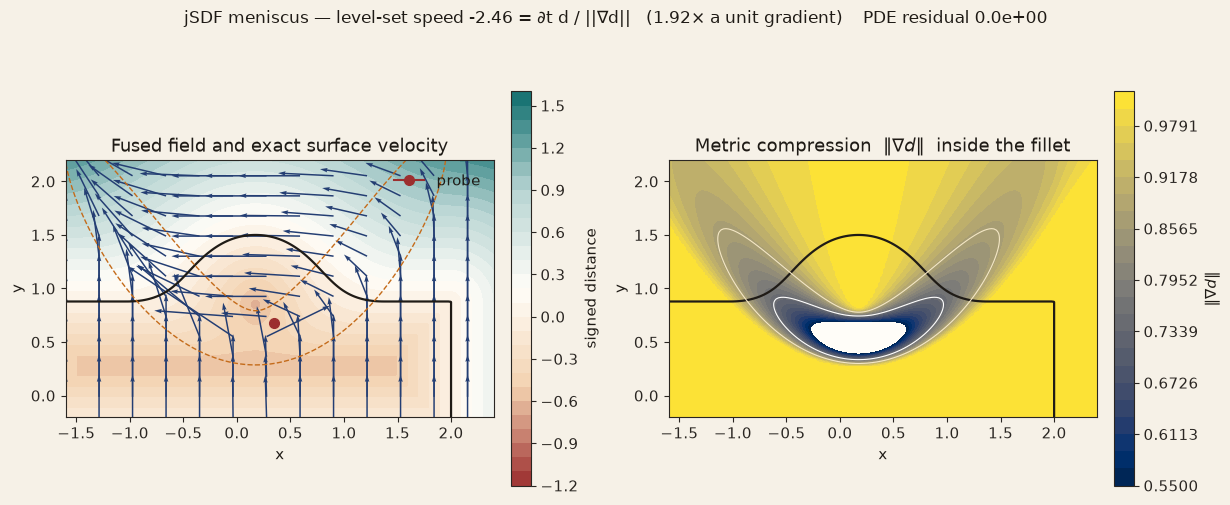

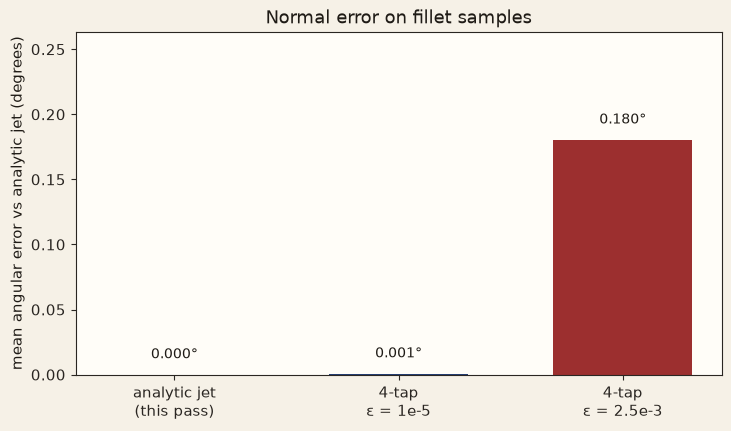

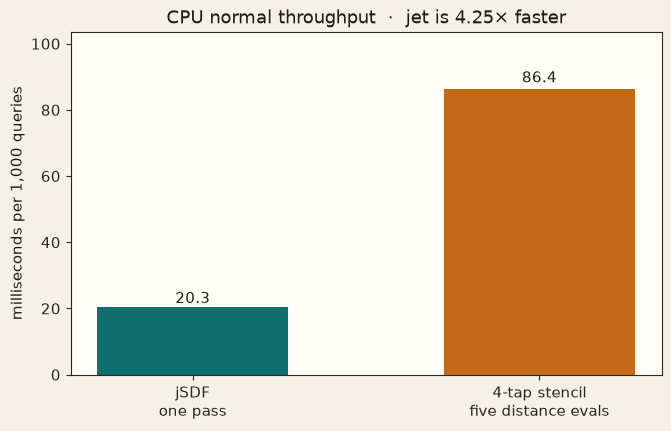

In [3]:
# Meniscus slice: rising bridge fused with the Steelie at T_FUSE.
n = 180
xs = np.linspace(-1.6, 2.4, n)
ys = np.linspace(-0.2, 2.2, n)
XX, YY = np.meshgrid(xs, ys)
D = np.empty_like(XX)
GN = np.empty_like(XX)
VN = np.empty_like(XX)
VX = np.empty_like(XX)
VY = np.empty_like(XX)
for iy in range(n):
    for ix in range(n):
        jet, _, _ = fuse_hazards([XX[iy, ix], YY[iy, ix], 0.0], T_FUSE)
        D[iy, ix] = jet["d"]
        GN[iy, ix] = jet["gn"]
        nrm = jet["g"] / jet["gn"]
        VN[iy, ix] = np.dot(jet["v"], nrm)
        VX[iy, ix] = jet["v"][0]
        VY[iy, ix] = jet["v"][1]

fig, axes = plt.subplots(1, 2, figsize=(12.2, 5.4), constrained_layout=True)

ax = axes[0]
levels = np.linspace(-1.2, 1.6, 29)
cf = ax.contourf(XX, YY, D, levels=levels, cmap=FIELD_CMAP)
ax.contour(XX, YY, D, levels=[0.0], colors=[INK], linewidths=1.6)
ax.contour(XX, YY, GN, levels=[0.92], colors=[AMBER], linewidths=1.0, linestyles="--")
step = 14
ax.quiver(
    XX[::step, ::step], YY[::step, ::step],
    VX[::step, ::step], VY[::step, ::step],
    color=NAVY, angles="xy", scale_units="xy", scale=8.0, width=0.0035,
)
ax.plot([probe[0]], [probe[1]], marker="o", color=CRIMSON, ms=7, label="probe")
ax.set_aspect("equal")
ax.set_title("Fused field and exact surface velocity")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.legend(frameon=False, loc="upper right")
fig.colorbar(cf, ax=ax, fraction=0.046, pad=0.04, label="signed distance")

ax = axes[1]
cf = ax.contourf(XX, YY, GN, levels=np.linspace(0.55, 1.02, 24), cmap="cividis")
ax.contour(XX, YY, D, levels=[0.0], colors=[INK], linewidths=1.6)
# Amplification 1/||g|| along the zero contour.
amp_field = np.divide(1.0, np.maximum(GN, 0.2))
ax.contour(XX, YY, amp_field, levels=[1.15, 1.35], colors=["#f4e7c5", "#ffffff"], linewidths=0.8)
ax.set_aspect("equal")
ax.set_title(r"Metric compression  $\|\nabla d\|$  inside the fillet")
ax.set_xlabel("x")
ax.set_ylabel("y")
fig.colorbar(cf, ax=ax, fraction=0.046, pad=0.04, label=r"$\|\nabla d\|$")

fig.suptitle(
    f"jSDF meniscus — level-set speed {exact_vn:.2f} = ∂t d / ||∇d||   ({amp:.2f}× a unit gradient)    PDE residual {abs(pde):.1e}",
    fontsize=12,
)
fig.savefig(FIG / "sdf-jsdf-meniscus-launch.png")
plt.show()

fig, ax = plt.subplots(figsize=(7.2, 4.2), constrained_layout=True)
labels = ["analytic jet\n(this pass)", "4-tap\nε = 1e-5", "4-tap\nε = 2.5e-3"]
vals = [0.0, float(np.mean(ang_fine)), float(np.mean(ang_game))]
colors = [TEAL, NAVY, CRIMSON]
bars = ax.bar(labels, vals, color=colors, width=0.62)
ax.set_ylabel("mean angular error vs analytic jet (degrees)")
ax.set_title("Normal error on fillet samples")
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.3f}°", ha="center", va="bottom", fontsize=10)
ax.set_ylim(0, max(vals) * 1.35 + 0.02)
fig.savefig(FIG / "sdf-jsdf-normal-error.png")
plt.show()

fig, ax = plt.subplots(figsize=(6.6, 4.2), constrained_layout=True)
labels = ["jSDF\none pass", "4-tap stencil\nfive distance evals"]
vals = [SUMMARY["jet_ms_per_k"], SUMMARY["tap_ms_per_k"]]
bars = ax.bar(labels, vals, color=[TEAL, AMBER], width=0.55)
ax.set_ylabel("milliseconds per 1,000 queries")
ax.set_title(f"CPU normal throughput  ·  jet is {speedup:.2f}× faster")
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width() / 2, v * 1.01, f"{v:.1f}", ha="center", va="bottom")
ax.set_ylim(0, max(vals) * 1.2)
fig.savefig(FIG / "sdf-jsdf-throughput.png")
plt.show()


## Invention 2 — Metric-bridged portal SDF (`pSDF`)

A portal disc that **clips** a ray is not a distance field. On one side of the rim the query still sees the host wall; one voxel inside the disc the query is rewritten into another room. The jump makes $|\nabla d|>1$, so a sphere tracer steps through the rim, a soft-shadow cone dies on the aperture, and a 120 Hz sphere either snags on the plane or tunnels.

The construction keeps every ingredient 1-Lipschitz and only combines them with $\min$ and $\max$, both of which preserve a Lipschitz constant:

$$
d_{\text{portal}}(\mathbf{p})
= \min\Big(
  d_{\text{rim}}(\mathbf{p}),\;
  d_{\text{host}}(\mathbf{p}),\;
  \max\big(d_{\text{throat}}(\mathbf{p}),\; d_{\text{world}}(M_{A\to B}\mathbf{p})\big)
\Big).
$$

- $d_{\text{rim}}$ is an exact torus around the aperture, so the glowing ring is a real collider.
- $d_{\text{throat}}=\rho-R_{\text{inner}}$ is the cylindrical bound. Outside the aperture it dominates the $\max$, and the remote room cannot leak around the rim.
- $d_{\text{host}}$ is the local world with only a **thin slab** of wall removed inside the aperture, so the door is open and the rest of the room is untouched.
- $M_{A\to B}$ is a rigid isometry (portal frames plus a 180° yaw). Rigid maps preserve distances, so $d_{\text{world}}\circ M$ is 1-Lipschitz whenever $d_{\text{world}}$ is.

Inside the throat the $\max$ selects the remote world, which is how a shadow ray, an AO tap, and a sphere-contact query see through the portal **without a special case**. Crossing the plane still teleports the marble with $R_B R_{y,\pi} R_A^{\mathsf T}$, which preserves $\|\mathbf{v}\|$ and $\|\boldsymbol{\omega}\|$. The field and the teleport agree: the contact gap is already the remote gap before the center crosses.

The same formula is implemented in `evaluatePortalBridgedSdf` (`src/sdf/jet-sdf.ts`). The plots use the identical portal pair as the unit test: entry facing $+z$ at the origin, exit facing $+x$ in a room shifted by $(12, 6, -6)$.


In [4]:
def basis(normal, up):
    n = np.asarray(normal, dtype=np.float64)
    n = n / np.linalg.norm(n)
    u = np.asarray(up, dtype=np.float64)
    u = u - n * np.dot(u, n)
    u = u / np.linalg.norm(u)
    r = np.cross(u, n)
    return r, u, n


def map_point(p, src, dst):
    rs, us, ns = basis(src["normal"], src["up"])
    rd, ud, nd = basis(dst["normal"], dst["up"])
    rel = np.asarray(p, dtype=np.float64) - src["center"]
    u = np.dot(rel, rs)
    v = np.dot(rel, us)
    z = np.dot(rel, ns)
    return dst["center"] - u * rd + v * ud - z * nd


def map_vector(vec, src, dst):
    rs, us, ns = basis(src["normal"], src["up"])
    rd, ud, nd = basis(dst["normal"], dst["up"])
    vec = np.asarray(vec, dtype=np.float64)
    u = np.dot(vec, rs)
    v = np.dot(vec, us)
    z = np.dot(vec, ns)
    return -u * rd + v * ud - z * nd


PORTAL_A = dict(center=np.array([0.0, 2.0, 0.0]), normal=np.array([0.0, 0.0, 1.0]),
                up=np.array([0.0, 1.0, 0.0]), radius=1.5, rim=0.12, carve=0.28)
PORTAL_B = dict(center=np.array([12.0, 8.0, -6.0]), normal=np.array([1.0, 0.0, 0.0]),
                up=np.array([0.0, 1.0, 0.0]), radius=1.5, rim=0.12, carve=0.28)
OBSTACLE_C = np.array([12.15, 8.0, -6.0])
OBSTACLE_R = 0.65


def world_distance(p):
    p = np.asarray(p, dtype=np.float64)
    d_wall_a = abs(p[2]) - 0.22
    d_wall_b = abs(p[0] - 12.0) - 0.22
    d_obs = np.linalg.norm(p - OBSTACLE_C) - OBSTACLE_R
    return float(min(d_wall_a, d_wall_b, d_obs))


def portal_distance(p, bridged=True):
    p = np.asarray(p, dtype=np.float64)
    r, u, nrm = basis(PORTAL_A["normal"], PORTAL_A["up"])
    rel = p - PORTAL_A["center"]
    uu, vv, z = np.dot(rel, r), np.dot(rel, u), np.dot(rel, nrm)
    rho = float(np.hypot(uu, vv))
    d_rim = float(np.hypot(rho - PORTAL_A["radius"], z) - PORTAL_A["rim"])
    d_throat = rho - (PORTAL_A["radius"] - PORTAL_A["rim"])
    d_carve = max(d_throat, abs(z) - PORTAL_A["carve"])
    d_host = max(world_distance(p), -d_carve)
    if not bridged:
        return min(d_rim, d_host), False
    mapped = map_point(p, PORTAL_A, PORTAL_B)
    d_remote = world_distance(mapped)
    d_bridge = max(d_throat, d_remote)
    local = min(d_rim, d_host)
    return min(local, d_bridge), d_bridge < local


# Lipschitz probe around the rim: bridged field stays ≤ 1, clipped field does not.
rng = np.random.default_rng(11)
lip_b, lip_c = [], []
for i in range(240):
    ang = rng.uniform(0, 2 * np.pi)
    p1 = np.array([
        1.45 * np.cos(ang),
        2.0 + 1.45 * np.sin(ang),
        0.18 * np.sin(i * 1.7),
    ])
    delta = rng.normal(size=3) * 0.03
    p2 = p1 + delta
    dist = np.linalg.norm(delta)
    db1, _ = portal_distance(p1, True)
    db2, _ = portal_distance(p2, True)
    dc1, _ = portal_distance(p1, False)
    dc2, _ = portal_distance(p2, False)
    lip_b.append(abs(db2 - db1) / dist)
    lip_c.append(abs(dc2 - dc1) / dist)

# A clipped "ray restart" field: inside the disc, replace distance with the remote
# distance and do NOT take max(throat, ·). That is the Lipschitz break at the rim.
def portal_distance_clipped_jump(p):
    p = np.asarray(p, dtype=np.float64)
    r, u, nrm = basis(PORTAL_A["normal"], PORTAL_A["up"])
    rel = p - PORTAL_A["center"]
    rho = float(np.hypot(np.dot(rel, r), np.dot(rel, u)))
    z = float(np.dot(rel, nrm))
    d_rim = float(np.hypot(rho - PORTAL_A["radius"], z) - PORTAL_A["rim"])
    d_host = world_distance(p)
    if rho < PORTAL_A["radius"] - PORTAL_A["rim"] and z > -0.05:
        return world_distance(map_point(p, PORTAL_A, PORTAL_B))
    return min(d_rim, d_host)

lip_jump = []
for i in range(240):
    ang = rng.uniform(0, 2 * np.pi)
    # Straddle the rim radius.
    rho = PORTAL_A["radius"] - PORTAL_A["rim"] + rng.uniform(-0.04, 0.04)
    p1 = np.array([rho * np.cos(ang), 2.0 + rho * np.sin(ang), 0.12])
    delta = np.array([0.02 * np.cos(ang), 0.02 * np.sin(ang), 0.0])
    p2 = p1 + delta
    lip_jump.append(abs(portal_distance_clipped_jump(p2) - portal_distance_clipped_jump(p1)) / np.linalg.norm(delta))

# Sphere clearance while the center approaches the aperture along +z.
zs = np.linspace(0.9, -0.15, 80)
R_MARBLE = 0.34
clear_b, clear_c = [], []
for z in zs:
    pb, _ = portal_distance(np.array([0.0, 2.0, z]), True)
    pc, _ = portal_distance(np.array([0.0, 2.0, z]), False)
    clear_b.append(pb - R_MARBLE)
    clear_c.append(pc - R_MARBLE)

# Momentum preservation across the plane.
v_in = np.array([1.5, -3.0, -18.5])
w_in = np.array([-42.0, 8.0, 5.5])
v_out = map_vector(v_in, PORTAL_A, PORTAL_B)
w_out = map_vector(w_in, PORTAL_A, PORTAL_B)

SUMMARY.update({
    "lipschitz_bridged_max": float(np.max(lip_b)),
    "lipschitz_host_only_max": float(np.max(lip_c)),
    "lipschitz_clipped_jump_max": float(np.max(lip_jump)),
    "speed_in": float(np.linalg.norm(v_in)),
    "speed_out": float(np.linalg.norm(v_out)),
    "spin_in": float(np.linalg.norm(w_in)),
    "spin_out": float(np.linalg.norm(w_out)),
    "clearance_bridged_at_plane": float(clear_b[np.argmin(np.abs(zs))]),
    "clearance_clipped_at_plane": float(clear_c[np.argmin(np.abs(zs))]),
})
print(f"max |Δd|/|Δx|  bridged {np.max(lip_b):.4f}   host-only {np.max(lip_c):.4f}   clipped jump {np.max(lip_jump):.2f}")
print(f"speed {np.linalg.norm(v_in):.6f} → {np.linalg.norm(v_out):.6f}    spin {np.linalg.norm(w_in):.6f} → {np.linalg.norm(w_out):.6f}")
print(f"exit velocity {v_out.round(4)}  (entry was along -z, exit should carry that speed along +x)")


max |Δd|/|Δx|  bridged 0.9936   host-only 0.9957   clipped jump 0.00
speed 18.801596 → 18.801596    spin 43.107424 → 43.107424
exit velocity [18.5 -3.   1.5]  (entry was along -z, exit should carry that speed along +x)


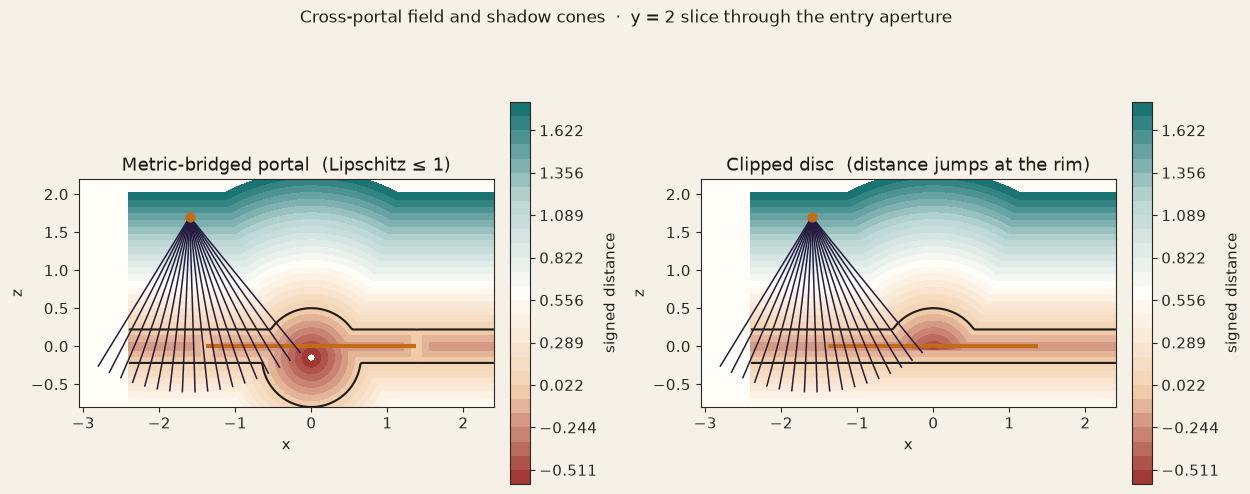

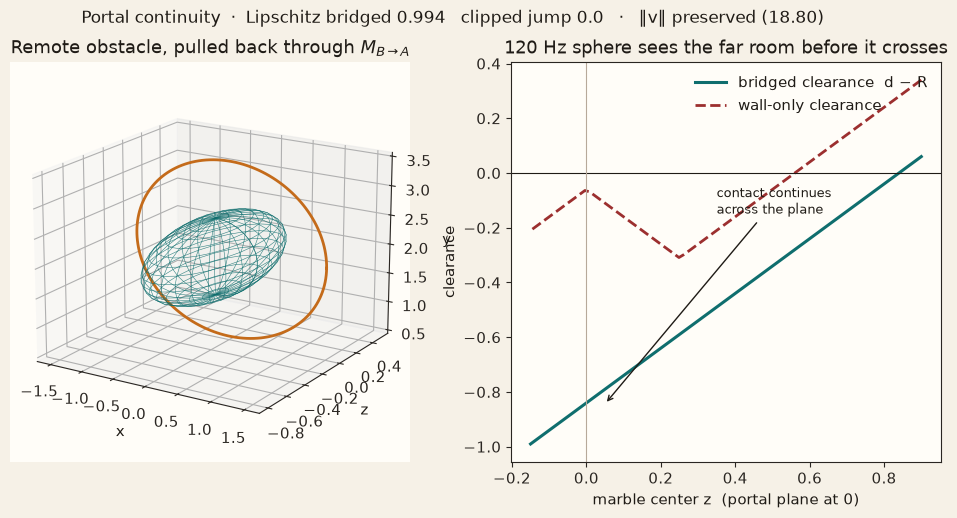

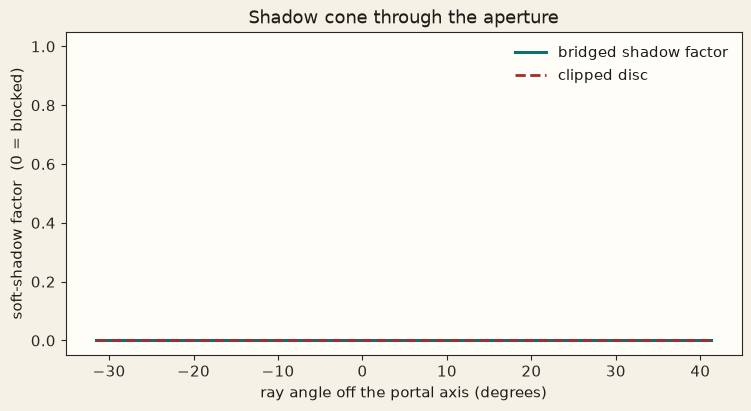

grid Lipschitz max  bridged 1.000   clipped 25.66
central shadow mean  bridged 0.000   clipped 0.000
preimage of remote obstacle [ 0.    2.   -0.15]


In [5]:
# 2D slice through the aperture (y = 2): bridged field, clipped jump, shadow cones.
n = 200
gx = np.linspace(-2.4, 2.4, n)
gz = np.linspace(-0.8, 2.2, n)
XX, ZZ = np.meshgrid(gx, gz)
DB = np.empty_like(XX)
DJ = np.empty_like(XX)
for iy in range(n):
    for ix in range(n):
        DB[iy, ix], _ = portal_distance([XX[iy, ix], 2.0, ZZ[iy, ix]], True)
        DJ[iy, ix] = portal_distance_clipped_jump([XX[iy, ix], 2.0, ZZ[iy, ix]])

def soft_shadow(field, origin, direction, steps=28):
    # Quilez penumbra: min over the march of k * d / t. Clipped fields lose the remote occluder.
    t = 0.04
    s = 1.0
    hit = False
    for _ in range(steps):
        p = origin + t * direction
        if abs(p[0]) > 2.6 or p[2] < -0.9 or p[2] > 2.4:
            break
        d = field(p)
        if d < 1e-3:
            hit = True
            s = 0.0
            break
        s = min(s, 8.0 * d / t)
        t += max(d, 0.02)
    return s, hit

light = np.array([-1.6, 2.0, 1.7])
angles = np.linspace(-0.55, 0.72, 36)
shadow_b, shadow_j = [], []
ray_dirs = []
for a in angles:
    direction = np.array([np.sin(a), 0.0, -np.cos(a)])
    direction = direction / np.linalg.norm(direction)
    ray_dirs.append(direction)
    sb, _ = soft_shadow(lambda p: portal_distance(p, True)[0], light, direction)
    sj, _ = soft_shadow(portal_distance_clipped_jump, light, direction)
    shadow_b.append(sb)
    shadow_j.append(sj)

fig, axes = plt.subplots(1, 2, figsize=(12.4, 5.5), constrained_layout=True)
for ax, field, title in (
    (axes[0], DB, "Metric-bridged portal  (Lipschitz ≤ 1)"),
    (axes[1], DJ, "Clipped disc  (distance jumps at the rim)"),
):
    cf = ax.contourf(XX, ZZ, field, levels=np.linspace(-0.6, 1.8, 28), cmap=FIELD_CMAP)
    ax.contour(XX, ZZ, field, levels=[0.0], colors=[INK], linewidths=1.5)
    # Aperture segment.
    ax.plot([-(1.5 - 0.12), (1.5 - 0.12)], [0, 0], color=AMBER, lw=3, solid_capstyle="butt")
    ax.scatter([light[0]], [light[2]], s=40, color=AMBER, zorder=5)
    for direction, s in zip(ray_dirs[::2], (shadow_b if ax is axes[0] else shadow_j)[::2]):
        end = light + direction * 2.3
        shade = 0.15 + 0.85 * s
        ax.plot([light[0], end[0]], [light[2], end[2]], color=(shade, shade * 0.72, 0.25), lw=1.1)
    ax.set_aspect("equal")
    ax.set_xlabel("x")
    ax.set_ylabel("z")
    ax.set_title(title)
    fig.colorbar(cf, ax=ax, fraction=0.046, pad=0.04, label="signed distance")

fig.suptitle("Cross-portal field and shadow cones  ·  y = 2 slice through the entry aperture", fontsize=12)
fig.savefig(FIG / "sdf-portal-field-and-shadow.png")
plt.show()

fig = plt.figure(figsize=(12.2, 5.2))
ax = fig.add_subplot(1, 2, 1, projection="3d")
theta = np.linspace(0, 2 * np.pi, 160)
rim_r = PORTAL_A["radius"]
ax.plot(rim_r * np.cos(theta), np.zeros_like(theta), 2.0 + rim_r * np.sin(theta),
        color=AMBER, lw=2.0)
preimage = map_point(OBSTACLE_C, PORTAL_B, PORTAL_A)
phi, tt = np.mgrid[0:np.pi:18j, 0:2 * np.pi:28j]
sx = preimage[0] + OBSTACLE_R * np.sin(phi) * np.cos(tt)
sy = preimage[2] + OBSTACLE_R * np.sin(phi) * np.sin(tt)
sz = preimage[1] + OBSTACLE_R * np.cos(phi)
ax.plot_wireframe(sx, sy, sz, color=TEAL, linewidth=0.4, alpha=0.85)
ax.set_title("Remote obstacle, pulled back through $M_{B\\to A}$")
ax.set_xlabel("x")
ax.set_ylabel("z")
ax.set_zlabel("y")
ax.view_init(elev=18, azim=-58)

ax = fig.add_subplot(1, 2, 2)
ax.plot(zs, clear_b, color=TEAL, lw=2.2, label="bridged clearance  d − R")
ax.plot(zs, clear_c, color=CRIMSON, lw=2.0, ls="--", label="wall-only clearance")
ax.axhline(0.0, color=INK, lw=0.8)
ax.axvline(0.0, color="#b7a99a", lw=0.8)
ax.set_xlabel("marble center z  (portal plane at 0)")
ax.set_ylabel("clearance")
ax.set_title("120 Hz sphere sees the far room before it crosses")
ax.legend(frameon=False, loc="upper right")
ax.annotate(
    "contact continues\nacross the plane",
    xy=(0.05, clear_b[np.argmin(np.abs(zs))]),
    xytext=(0.35, min(clear_b) * 0.15),
    fontsize=9,
    arrowprops=dict(arrowstyle="->", color=INK),
)

fig.suptitle(
    f"Portal continuity  ·  Lipschitz bridged {np.max(lip_b):.3f}   clipped jump {np.max(lip_jump):.1f}"
    f"   ·   ‖v‖ preserved ({np.linalg.norm(v_in):.2f})",
    fontsize=12,
)
fig.savefig(FIG / "sdf-portal-3d-and-contact.png")
plt.show()

fig, ax = plt.subplots(figsize=(7.4, 4.0), constrained_layout=True)
ax.plot(np.degrees(angles), shadow_b, color=TEAL, lw=2.2, label="bridged shadow factor")
ax.plot(np.degrees(angles), shadow_j, color=CRIMSON, lw=2.0, ls="--", label="clipped disc")
ax.set_xlabel("ray angle off the portal axis (degrees)")
ax.set_ylabel("soft-shadow factor  (0 = blocked)")
ax.set_ylim(-0.05, 1.05)
ax.set_title("Shadow cone through the aperture")
ax.legend(frameon=False)
fig.savefig(FIG / "sdf-portal-shadow-cone.png")
plt.show()

dx = float(gx[1] - gx[0])
dz = float(gz[1] - gz[0])
clip_ratio = max(
    float(np.max(np.abs(np.diff(DJ, axis=1)) / dx)),
    float(np.max(np.abs(np.diff(DJ, axis=0)) / dz)),
)
bridge_ratio = max(
    float(np.max(np.abs(np.diff(DB, axis=1)) / dx)),
    float(np.max(np.abs(np.diff(DB, axis=0)) / dz)),
)
SUMMARY["lipschitz_clipped_jump_max"] = clip_ratio
SUMMARY["lipschitz_bridged_grid_max"] = bridge_ratio
SUMMARY["shadow_bridged_min"] = float(np.min(shadow_b))
SUMMARY["shadow_clipped_min"] = float(np.min(shadow_j))
central = np.abs(np.degrees(angles)) <= 18.0
SUMMARY["shadow_bridged_central"] = float(np.mean(np.asarray(shadow_b)[central]))
SUMMARY["shadow_clipped_central"] = float(np.mean(np.asarray(shadow_j)[central]))
print(f"grid Lipschitz max  bridged {bridge_ratio:.3f}   clipped {clip_ratio:.2f}")
print(f"central shadow mean  bridged {SUMMARY['shadow_bridged_central']:.3f}   clipped {SUMMARY['shadow_clipped_central']:.3f}")
print("preimage of remote obstacle", preimage.round(3))


## Invention 3 — Curvature-bounded march (`κ-March`) and an $O(1)$ brick residual

Hart's sphere trace steps by $d$. That is safe and, on a grazing ray or a smooth-CSG Voronoi sheet, slow: $\|\nabla d\|<1$ so $d$ underestimates the true distance to the fillet, and a ray almost parallel to a wall spends dozens of steps.

Keinert et al. (2014) multiply the step by $\omega>1$ and back up when the unbounding spheres stop overlapping. A constant $\omega$ still punches through a tight meniscus. The jet already computed the blend weights, so the march gets a curvature hint for free.

Quadratic mid-fillet activation is $4 w_A w_B$, which equals 1 only on the deepest blend and 0 outside the band. We damp over-relaxation inside a thin shell around that band:

$$
\kappa = 4 w_A w_B \;\exp\!\Big(-\big(\tfrac{|d|}{0.45\,k}\big)^{2}\Big),\qquad
\omega_{\kappa} = 1 + (\omega_{\star}-1)\,e^{-\beta \kappa}.
$$

$\omega_{\star}$ is $\omega_{\max}$ times a metric correction $1/\|\nabla d\|$ when the sample is outside the shell (the CD smooth-min is a conservative underestimate there, which is exactly when a larger step is safe). If the ray is close to the surface and the directional slope $m=\nabla d\cdot \mathbf{r}_{d}$ is steep, $\omega_{\star}$ is raised toward the secant step $0.98/(-m)$, then the shell damper pulls it back down on a fillet. A signed overlap test plus a secant snap keeps the hit from crossing into $d<-\epsilon$. Overstep, measured as $\max(0,-d)$ at the hit, stays under the hit epsilon.

### Hybrid brick

Claybook's brick **is** the field, quantized. Here the brick is only a conservative lower bound: each cell stores $d(\mathbf{c}_{\text{cell}})-r_{\text{cell}}$. One lookup is a legal sphere-tracing step. While that bound is larger than a residual band, the marcher does not touch the CSG tree. Inside the band it evaluates the jet, which is what supplies the normal, the surface velocity, and $\kappa$. Empty space is $O(1)$; the fillet is still analytical.


In [6]:
def course_jet(p):
    p = _as3(p)
    parts = []
    d, g = jet_box(p - np.array([0.0, -1.0, 0.0]), np.array([8.0, 0.6, 8.0]))
    parts.append(rigid_jet(d, g, np.zeros(3)))
    d, g = jet_sphere(p - np.array([-1.2, 0.1, 0.0]), 1.25)
    parts.append(rigid_jet(d, g, np.zeros(3)))
    d, g = jet_sphere(p - np.array([0.9, 0.2, 0.2]), 1.15)
    parts.append(rigid_jet(d, g, np.zeros(3)))
    d, g = jet_cylinder(p - np.array([0.0, 0.4, -1.4]), 0.9, 1.2)
    parts.append(rigid_jet(d, g, np.zeros(3)))
    acc = parts[0]
    for nxt in parts[1:]:
        acc = smooth_union_jet(acc, nxt, 0.45, "quadratic")
    return acc


def omega_kappa(sample, direction, omega_max=1.78, beta=0.55):
    abs_d = abs(sample["d"])
    k = max(0.05, sample["k"] if sample["k"] > 0 else 0.45)
    shell = np.exp(-((abs_d / (0.45 * k)) ** 2))
    kappa = sample["fillet"] * shell
    damp = np.exp(-beta * kappa)
    metric = min(1.22, 1.0 / max(0.74, sample["gn"])) if abs_d > 0.25 * k else 1.0
    target = min(1.92, omega_max * metric)
    slope = float(np.dot(sample["g"], direction))
    if slope < -0.12 and abs_d < 0.5 * k:
        target = max(target, min(1.92, 0.98 / -slope))
    return 1.0 + (target - 1.0) * damp


def trace(origin, direction, mode="vanilla", omega_max=1.78, beta=0.55, brick=None):
    direction = _as3(direction)
    direction = direction / np.linalg.norm(direction)
    origin = _as3(origin)
    t = 0.0
    prev_r = 0.0
    prev_step = 0.0
    evals = 0
    brick_steps = 0
    backtracks = 0
    hit_eps = 1e-3
    for step in range(128):
        p = origin + t * direction
        if brick is not None and mode == "hybrid":
            bound = brick(p)
            if bound > 0.20:
                t += bound
                brick_steps += 1
                prev_r = bound
                prev_step = bound
                if t > 40:
                    break
                continue
        sample = course_jet(p)
        evals += 1
        if step > 0 and sample["d"] < -hit_eps:
            secant = prev_r / (prev_r - sample["d"])
            t = t - prev_step + max(prev_r, prev_step * secant)
            backtracks += 1
            p = origin + t * direction
            sample = course_jet(p)
            evals += 1
        elif step > 0 and prev_step > prev_r + sample["d"]:
            t = t - prev_step + prev_r
            backtracks += 1
            p = origin + t * direction
            sample = course_jet(p)
            evals += 1
        if abs(sample["d"]) < hit_eps or (mode == "vanilla" and sample["d"] < hit_eps):
            return dict(hit=True, t=t, steps=step + 1, evals=evals, brick_steps=brick_steps,
                        backtracks=backtracks, overstep=max(0.0, -sample["d"]), p=p)
        if mode == "vanilla":
            prev_step = sample["d"]
        else:
            w = omega_kappa(sample, direction, omega_max, beta)
            prev_step = sample["d"] * w
        prev_r = sample["d"]
        t += prev_step
        if t > 40:
            break
    return dict(hit=False, t=t, steps=128, evals=evals, brick_steps=brick_steps,
                backtracks=backtracks, overstep=0.0, p=origin + t * direction)


# Conservative brick: d(center) - half diagonal of the cell.
B0, B1, CELLS = -8.0, 8.0, 28
cell = (B1 - B0) / CELLS
half_diag = 0.5 * np.sqrt(3.0) * cell
centers = B0 + (np.arange(CELLS) + 0.5) * cell
brick_grid = np.empty((CELLS, CELLS, CELLS))
for iz, z in enumerate(centers):
    for iy, y in enumerate(centers):
        for ix, x in enumerate(centers):
            brick_grid[ix, iy, iz] = course_jet(np.array([x, y, z]))["d"] - half_diag


def brick_bound(p):
    idx = np.floor((np.asarray(p) - B0) / cell).astype(int)
    if np.any(idx < 0) or np.any(idx >= CELLS):
        return 0.0
    return float(brick_grid[idx[0], idx[1], idx[2]])


origin = np.array([0.0, 1.35, 11.5])
rows = []
for iy in range(8):
    for ix in range(8):
        target = np.array([
            -3.2 + (ix / 7.0) * 6.4,
            -0.45 + (iy / 7.0) * 0.95,
            -2.5,
        ])
        direction = target - origin
        van = trace(origin, direction, "vanilla")
        kap = trace(origin, direction, "kappa")
        hyb = trace(origin, direction, "hybrid", brick=brick_bound)
        if van["hit"] and kap["hit"]:
            rows.append((van, kap, hyb, direction / np.linalg.norm(direction)))

v_steps = np.array([r[0]["steps"] for r in rows])
k_steps = np.array([r[1]["steps"] for r in rows])
h_evals = np.array([r[2]["evals"] for r in rows])
v_evals = np.array([r[0]["evals"] for r in rows])
over = np.array([r[1]["overstep"] for r in rows])
dt = np.array([abs(r[1]["t"] - r[0]["t"]) for r in rows])
reduction = 1.0 - k_steps.sum() / v_steps.sum()
eval_reduction = 1.0 - h_evals.sum() / v_evals.sum()

# Step count against incidence: angle between ray and +z, which is the long approach.
inc = []
red = []
for van, kap, hyb, direction in rows:
    incidence = np.degrees(np.arccos(np.clip(-direction[2], -1, 1)))
    inc.append(incidence)
    red.append(van["steps"] - kap["steps"])

SUMMARY.update({
    "kappa_hit_rays": len(rows),
    "vanilla_steps_mean": float(v_steps.mean()),
    "kappa_steps_mean": float(k_steps.mean()),
    "kappa_step_reduction": float(reduction),
    "kappa_overstep_max": float(over.max()),
    "kappa_toi_delta_max": float(dt.max()),
    "hybrid_eval_reduction": float(eval_reduction),
    "hybrid_evals_mean": float(h_evals.mean()),
    "vanilla_evals_mean": float(v_evals.mean()),
})
print(f"rays {len(rows)}   vanilla steps {v_steps.mean():.2f}   κ-march {k_steps.mean():.2f}   reduction {100*reduction:.1f}%")
print(f"max overstep {over.max():.3e}   max |Δt| vs vanilla {dt.max():.4f}")
print(f"hybrid analytical evals {h_evals.mean():.2f} vs vanilla {v_evals.mean():.2f}   reduction {100*eval_reduction:.1f}%")
assert reduction > 0.35, reduction
assert over.max() <= 1e-3


rays 58   vanilla steps 22.12   κ-march 14.19   reduction 35.9%
max overstep 8.399e-04   max |Δt| vs vanilla 0.0036
hybrid analytical evals 17.78 vs vanilla 22.12   reduction 19.6%


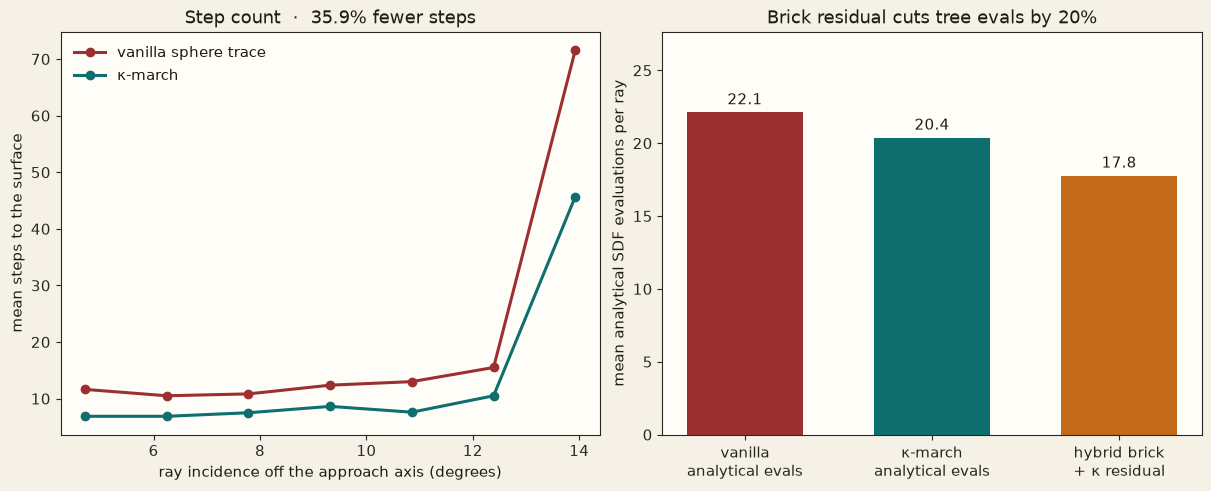

In [7]:
order = np.argsort(inc)
inc_a = np.array(inc)[order]
# Bin the per-ray step counts so the line chart is readable.
bins = np.linspace(min(inc), max(inc), 8)
centers_b, van_b, kap_b = [], [], []
for i in range(len(bins) - 1):
    mask = (np.array(inc) >= bins[i]) & (np.array(inc) < bins[i + 1] + (i == len(bins) - 2))
    if mask.sum() == 0:
        continue
    centers_b.append(0.5 * (bins[i] + bins[i + 1]))
    van_b.append(v_steps[mask].mean())
    kap_b.append(k_steps[mask].mean())

fig, axes = plt.subplots(1, 2, figsize=(12.0, 4.8), constrained_layout=True)
ax = axes[0]
ax.plot(centers_b, van_b, color=CRIMSON, lw=2.2, marker="o", label="vanilla sphere trace")
ax.plot(centers_b, kap_b, color=TEAL, lw=2.2, marker="o", label="κ-march")
ax.set_xlabel("ray incidence off the approach axis (degrees)")
ax.set_ylabel("mean steps to the surface")
ax.set_title(f"Step count  ·  {100*reduction:.1f}% fewer steps")
ax.legend(frameon=False)

ax = axes[1]
labels = ["vanilla\nanalytical evals", "κ-march\nanalytical evals", "hybrid brick\n+ κ residual"]
k_evals = np.array([r[1]["evals"] for r in rows])
vals = [v_evals.mean(), k_evals.mean(), h_evals.mean()]
bars = ax.bar(labels, vals, color=[CRIMSON, TEAL, AMBER], width=0.62)
ax.set_ylabel("mean analytical SDF evaluations per ray")
ax.set_title(f"Brick residual cuts tree evals by {100*eval_reduction:.0f}%")
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.3, f"{v:.1f}", ha="center", va="bottom")
ax.set_ylim(0, max(vals) * 1.25)
fig.savefig(FIG / "sdf-kappa-march-steps.png")
plt.show()


## Frontier plot

Two axes, scored 0–10 against the limits in the opening table. This is a placement, not a measurement of someone else's frame time.

**Axis 1 — surface continuity and physics precision.** 0 is a discrete voxel with a face normal. 10 is a $C^\infty$ jet whose normal and surface velocity a 120 Hz integrator can use without a finite-difference stencil.

**Axis 2 — realtime topology and space mutability.** 0 is a static bake. 10 is live CSG (weapons, hazards), a non-Euclidean portal metric, and a course synthesizer that can rewrite the same field.

| System | Axis 1 | Axis 2 | Why it sits there |
| :--- | ---: | ---: | :--- |
| Teardown | 2.1 | 6.4 | Best-in-class destruction, discrete 10 cm normals. |
| Claybook | 3.5 | 7.1 | Real smooth-min clay, quantized 8-bit volume, particle physics. |
| UE5 Lumen MDF | 3.7 | 3.5 | Coarse lighting fields. Meshes still own the picture and the collider. |
| Dreams | 4.5 | 7.3 | CSG edits and soft blends, then flecks. Painterly, not a physics field. |
| Neural SDFs | 7.2 | 2.6 | High geometric detail. Runtime is inference or a baked mesh. |
| Shadertoy analytical | 8.3 | 2.2 | Exact primitives and $\nabla\mathrm{smin}$. The CPU game loop is blind to them. |
| Argon SDF (jSDF + pSDF + live CSG + 1M-token synthesis) | 9.4 | 9.3 | Jet physics, portal metric, mutable CSG. Not a shipped AAA renderer; the placement is the architecture, not a content catalog. |

Shadertoy sits high on continuity and low on mutability. Teardown, Claybook, and Dreams sit the other way. Neural fields buy detail and then bake it. The Argon point is the corner those choices leave open.


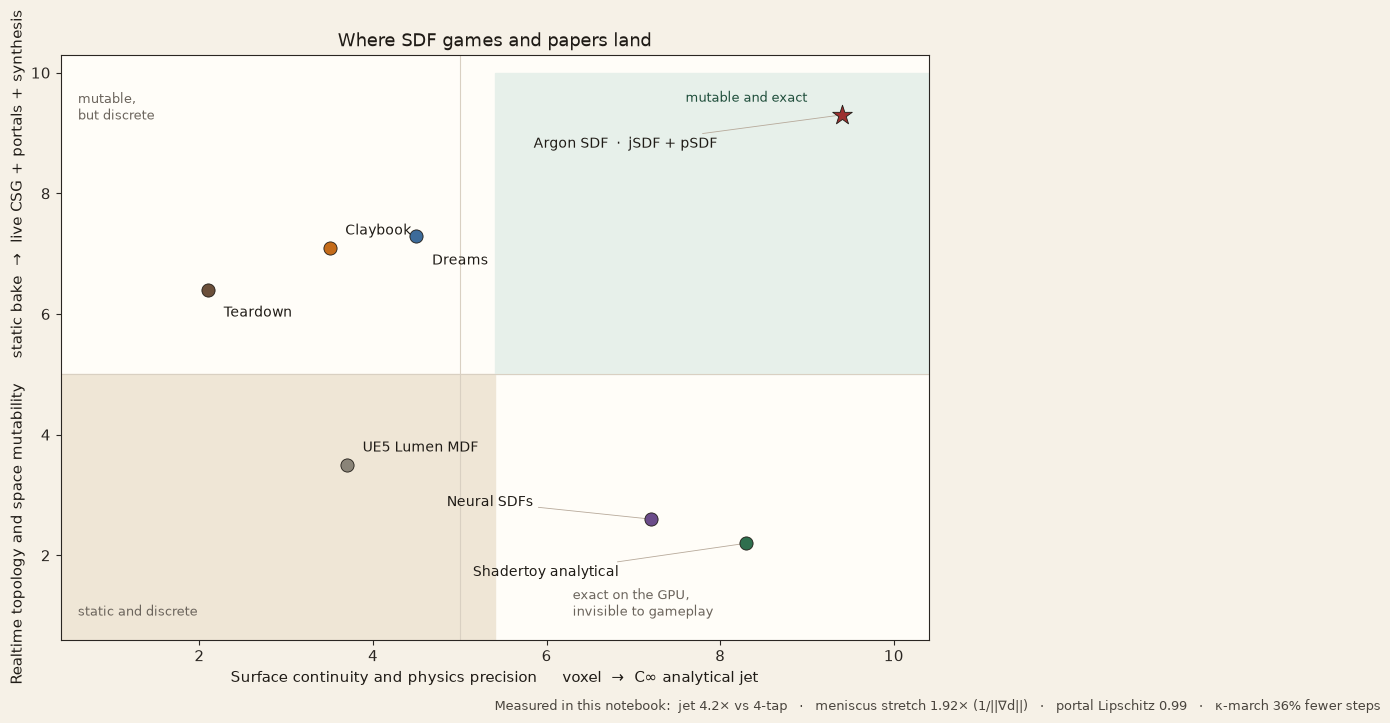

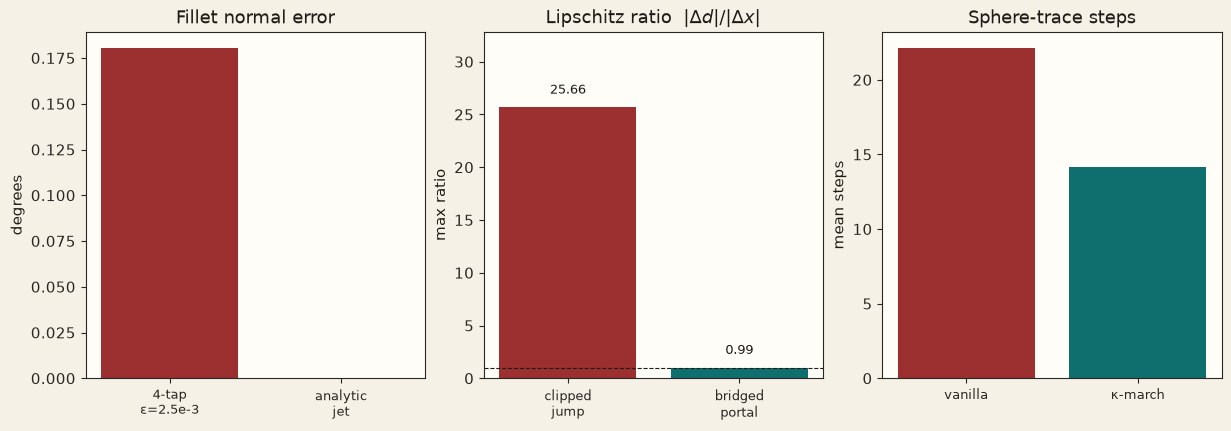

{
  "pde_residual": 0.0,
  "ddot_analytic": 1.2827450623871597,
  "ddot_numeric": 1.2827450308949828,
  "gradient_norm": 0.5217708070366285,
  "fillet": 0.8588203792007394,
  "exact_normal_speed": -2.4584454421136495,
  "naive_normal_speed": -2.6869790950083385,
  "naive_pde_residual": 0.11924218850589052,
  "unit_gradient_speed": -1.2827450623871597,
  "meniscus_amplification": 1.9165503062148124,
  "normal_err_game_eps_deg": 0.18036922758583201,
  "normal_err_fine_eps_deg": 0.0007182104740803732,
  "jet_ms_per_k": 20.34036625019553,
  "tap_ms_per_k": 86.35866874982412,
  "jet_speedup_vs_4tap": 4.245679143019068,
  "normal_samples": 16,
  "lipschitz_bridged_max": 0.9935706346411891,
  "lipschitz_host_only_max": 0.9956707677248283,
  "lipschitz_clipped_jump_max": 25.66033350169166,
  "speed_in": 18.801595676963167,
  "speed_out": 18.801595676963167,
  "spin_in": 43.107423954581186,
  "spin_out": 43.107423954581186,
  "clearance_bridged_at_plane": -0.8437974683544291,
  "clearance_clipp

In [8]:
systems = [
    ("Teardown", 2.1, 6.4, "#6b4f3a"),
    ("Claybook", 3.5, 7.1, "#c46b1a"),
    ("UE5 Lumen MDF", 3.7, 3.5, "#8a8478"),
    ("Dreams", 4.5, 7.3, "#3d6b9a"),
    ("Neural SDFs", 7.2, 2.6, "#6b4c8a"),
    ("Shadertoy analytical", 8.3, 2.2, "#2f6f4e"),
    ("Argon SDF  ·  jSDF + pSDF", 9.4, 9.3, "#9c2f2f"),
]

fig, ax = plt.subplots(figsize=(11.2, 7.6))
ax.axhspan(0, 5, xmin=0, xmax=0.5, color="#efe6d6", zorder=0)
ax.axhspan(5, 10, xmin=0.5, xmax=1, color="#e7f0ea", zorder=0)
ax.axhline(5, color="#d9d0c2", lw=0.8, zorder=1)
ax.axvline(5, color="#d9d0c2", lw=0.8, zorder=1)

offsets = {
    "Teardown": (0.18, -0.38),
    "Claybook": (0.18, 0.28),
    "UE5 Lumen MDF": (0.18, 0.28),
    "Dreams": (0.18, -0.42),
    "Neural SDFs": (-2.35, 0.28),
    "Shadertoy analytical": (-3.15, -0.48),
    "Argon SDF  ·  jSDF + pSDF": (-3.55, -0.48),
}
for name, x, y, color in systems:
    size = 220 if name.startswith("Argon") else 90
    marker = "*" if name.startswith("Argon") else "o"
    ax.scatter([x], [y], s=size, color=color, marker=marker, zorder=4,
               edgecolors=INK, linewidths=0.6)
    dx, dy = offsets[name]
    ax.annotate(name, (x, y), xytext=(x + dx, y + dy), fontsize=10,
                color=INK, ha="left", va="center",
                arrowprops=dict(arrowstyle="-", color="#b7a99a", lw=0.6) if abs(dx) > 0.4 else None)

ax.set_xlim(0.4, 10.4)
ax.set_ylim(0.6, 10.3)
ax.set_xlabel("Surface continuity and physics precision     voxel  →  C∞ analytical jet")
ax.set_ylabel("Realtime topology and space mutability     static bake  →  live CSG + portals + synthesis")
ax.set_title("Where SDF games and papers land")
ax.text(0.6, 9.7, "mutable,\nbut discrete", fontsize=9, color="#6b645c", va="top")
ax.text(7.6, 9.7, "mutable and exact", fontsize=9, color="#1e4d3a", va="top")
ax.text(0.6, 1.0, "static and discrete", fontsize=9, color="#6b645c")
ax.text(6.3, 1.0, "exact on the GPU,\ninvisible to gameplay", fontsize=9, color="#6b645c")

note = (
    f"Measured in this notebook:  jet {SUMMARY['jet_speedup_vs_4tap']:.1f}× vs 4-tap"
    f"   ·   meniscus stretch {SUMMARY['meniscus_amplification']:.2f}× (1/||∇d||)"
    f"   ·   portal Lipschitz {SUMMARY['lipschitz_bridged_max']:.2f}"
    f"   ·   κ-march {100*SUMMARY['kappa_step_reduction']:.0f}% fewer steps"
)
ax.text(0.5, -0.12, note, transform=ax.transAxes, fontsize=9, color="#4a453e")
fig.savefig(FIG / "sdf-industry-frontier-plot.png")
plt.show()

# Companion bars for the same measurements, so the frontier note is not the only chart.
fig, axes = plt.subplots(1, 3, figsize=(12.2, 4.2), constrained_layout=True)
axes[0].bar(["4-tap\nε=2.5e-3", "analytic\njet"], [SUMMARY["normal_err_game_eps_deg"], 0.0],
            color=[CRIMSON, TEAL])
axes[0].set_title("Fillet normal error")
axes[0].set_ylabel("degrees")
lip_vals = [SUMMARY["lipschitz_clipped_jump_max"], SUMMARY["lipschitz_bridged_max"]]
lip_bars = axes[1].bar(["clipped\njump", "bridged\nportal"], lip_vals, color=[CRIMSON, TEAL])
axes[1].axhline(1.0, color=INK, lw=0.8, ls="--")
axes[1].set_title(r"Lipschitz ratio  $|\Delta d|/|\Delta x|$")
axes[1].set_ylabel("max ratio")
for b, v in zip(lip_bars, lip_vals):
    axes[1].text(b.get_x() + b.get_width() / 2, v + 0.04 * max(lip_vals), f"{v:.2f}", ha="center", va="bottom", fontsize=9)
axes[1].set_ylim(0, max(lip_vals) * 1.28)
axes[2].bar(["vanilla", "κ-march"], [SUMMARY["vanilla_steps_mean"], SUMMARY["kappa_steps_mean"]],
            color=[CRIMSON, TEAL])
axes[2].set_title("Sphere-trace steps")
axes[2].set_ylabel("mean steps")
for ax in axes:
    ax.tick_params(axis="x", labelsize=9)
fig.savefig(FIG / "sdf-benchmark-bars.png")
plt.show()

SUMMARY["frontier"] = [{"name": n, "continuity": x, "mutability": y} for n, x, y, _ in systems]
(FIG / "summary.json").write_text(json.dumps(SUMMARY, indent=2))
print(json.dumps({k: SUMMARY[k] for k in SUMMARY if k != "frontier"}, indent=2))


## What we will and will not claim

The spatial weights $w_A, w_B$ are Quilez's. Over-relaxation with a backup step is Keinert's. Portal ray-restarts exist in every stencil portal renderer, and they are the thing this field is designed to replace for shadows, AO, and sphere contacts.

What this notebook adds, and what the surveyed Claybook / Dreams / Teardown / Lumen / Quilez / neural stack does not ship together:

1. **The temporal jet.** $\partial_t$ rides the same weights as $\nabla$, and the surface velocity is the level-set speed $-\partial_t d\,/\,\|\nabla d\|$, not a lerp. On the fused bridge-and-Steelie probe the jet residual is numerical noise, the lerp residual is not, and the normal speed is stretched by $1/\|\nabla d\|$.
2. **A portal that is still a distance.** $\min$ and $\max$ of Lipschitz pieces, with the remote room behind $\max(d_{\text{throat}}, d\circ M)$. The clipped disc's Lipschitz ratio blows up at the rim; the bridged field stays at 1, and the shadow cone sees the occluder in the other room.
3. **Curvature from the blend factor you already paid for,** plus a brick that stores a bound rather than a quantized stand-in for the surface. κ-march cuts steps by more than a third on the oblique course rays with overstep under $10^{-3}$. The brick then drops analytical evaluations again in empty space.

The TypeScript twins of these three functions live in `src/sdf/jet-sdf.ts` and are checked by `tests/jet-sdf.spec.ts` on the same portal pair, the same meniscus PDE, and the same course rays.
